<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Crypto Market Data](https://github.com/Query-farm/vgi-ccxt)

Candles, quotes, order books, trades and perpetual funding from 100+ crypto exchanges.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-ccxt/blob/main/notebooks/02_snapshot_values_need_their_units.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-ccxt/blob/main/notebooks/README.md)


## 02 · A common symbol does not make measurements interchangeable

A quote, a funding rate, an open-interest amount and resting book quantity answer different questions. Which comparisons survive an explicit units check? We will use the exchange roster and market definitions, retain failed fan-out rows, then compare reported open-interest value with a deliberately stated contract-unit assumption. A separate spot book shows how requested depth changes the displayed population.

**Every value is synthetic**, generated by the released worker's unchanged fixture. Names label stand-ins, not live venue behavior. The fixture intentionally exposes a limitation of casual unit conversion: its open-interest generator multiplies raw amount by price, while one contract definition has size 0.01. We will expose that disagreement rather than infer the amount's true unit. No credentials, accounts or trading calls are used.

### Run from GitHub or Colab
Run the short base-package installation cell, choose the visible parameter, then Run All. The released worker uses **explicit synthetic fixture mode** throughout this notebook; it is never a response to a live failure. The shared bootstrap verifies the unchanged fixture's hash. The local runner and separate experiment commands are in the [example notes](README.md).

In [1]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.50":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.50"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.50":
    raise RuntimeError("Install shared tools 0.3.50, restart, and Run All.")

In [2]:
DEPTH = 5  # Displayed levels per side; experiment: 10

In [3]:
import atexit
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

NOTEBOOK_DIR = prepare("ccxt")
fixture = NOTEBOOK_DIR / "fixtures.json"
fixture_hash = hashlib.sha256(fixture.read_bytes()).hexdigest()
assert fixture_hash == "6d4af927d0c7c98dcc51943d0ee54890e64269b2f5c5161e942911fdb387f4ed"
previous_fixture = os.environ.get("VGI_CCXT_FIXTURES")
os.environ["VGI_CCXT_FIXTURES"] = str(fixture.resolve())


def restore_fixture():
    if previous_fixture is None:
        os.environ.pop("VGI_CCXT_FIXTURES", None)
    else:
        os.environ["VGI_CCXT_FIXTURES"] = previous_fixture


atexit.register(restore_fixture)
%matplotlib inline
theme()
session = connect(globals())
con = session.connection
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
assert con.execute("SELECT current_setting('TimeZone')").fetchone()[0] == "UTC"
source_label = "SYNTHETIC · released worker FakeExchange · explicit fixtures.json · no live exchange requests"

assert type(DEPTH) is int and DEPTH in (5, 10)

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'ccxt' (TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-ccxt@v0.1.0 vgi-ccxt-worker');

,Success


### Establish identifiers, contracts and capability boundaries

The roster describes this fixture environment, not the real CCXT exchange population. Market definitions distinguish spot BTC/USDT from the settled perpetual BTC/USDT:USDT. A unified symbol aligns identifiers; `contract_size`, settlement currency and linear/inverse flags remain necessary context. We retain Kraken as a fan-out control even though this fixture has no matching perpetual.

In [5]:
%%sql
CREATE TABLE roster AS SELECT * FROM ccxt.main.exchanges;
CREATE TABLE contracts AS
SELECT * FROM ccxt.main.markets('binance') WHERE base='BTC' AND type='swap'
UNION ALL
SELECT * FROM ccxt.main.markets('okx') WHERE base='BTC' AND type='swap';
SELECT id,name,has_funding_rate_history,has_open_interest FROM roster ORDER BY id;
SELECT exchange,symbol,base,quote,settle,contract_size,linear,inverse
FROM contracts ORDER BY exchange,symbol;

,exchange,symbol,base,quote,settle,contract_size,linear,inverse
0,binance,BTC/USDT:USDT,BTC,USDT,USDT,1.00,True,False
1,okx,BTC/USDT:USDT,BTC,USDT,USDT,0.01,True,False


In [6]:
roster = con.execute(
    "SELECT id,name,has_ohlcv,has_trades,has_funding_rate_history,has_open_interest FROM roster ORDER BY id"
).df()
display(roster)
assert len(roster) == 4 and roster.id.is_unique
prose(
    f"The explicit fixture exposes **{len(roster)} exchange identities**, not the real library's 100+ integrations. Its roster marks **{int(roster.has_funding_rate_history.sum())}** as supporting funding history and **{int(roster.has_open_interest.sum())}** as supporting open interest. We keep this capability population distinct from the two selected BTC perpetual definitions and the three requested snapshot venues. A roster flag does not establish a valid symbol or a returned measurement; the next fan-out retains that evidence separately."
)

,id,name,has_ohlcv,has_trades,has_funding_rate_history,has_open_interest
0,binance,Binance,True,True,True,True
1,coinbase,Coinbase Advanced,True,True,False,False
2,kraken,Kraken,True,True,False,False
3,okx,OKX,True,True,True,True


The explicit fixture exposes **4 exchange identities**, not the real library's 100+ integrations. Its roster marks **2** as supporting funding history and **2** as supporting open interest. We keep this capability population distinct from the two selected BTC perpetual definitions and the three requested snapshot venues. A roster flag does not establish a valid symbol or a returned measurement; the next fan-out retains that evidence separately.

### Keep failures and distinguish current from settled funding

Each fan-out call emits one row per requested exchange; a failure remains an `error` row with NULL measurements. The ticker is a rolling quote summary, while `funding_rate` describes the upcoming settlement and carries its own interval. Neither is the historical funding series in Book 01. In this fixture the current-rate generator uses its configured eight-hour interval even after the historical generator's four-hour transition; the two synthetic contracts must not be conflated.

Open-interest amount is documented as contracts **or** base currency, depending on the exchange. The reported value is separate evidence. We explicitly test the *assumption* that amount is contracts using `amount × contract_size × ticker.last`. Equality would support that arithmetic only for these selected inputs; disagreement does not determine the true unit.

In [7]:
%%sql
CREATE TABLE quotes AS SELECT * FROM ccxt.main.ticker(['binance','okx','kraken'],'BTC/USDT:USDT');
CREATE TABLE funding_now AS SELECT * FROM ccxt.main.funding_rate(['binance','okx','kraken'],'BTC/USDT:USDT');
CREATE TABLE interest AS SELECT * FROM ccxt.main.open_interest(['binance','okx','kraken'],'BTC/USDT:USDT');
CREATE TABLE measurement_status AS
SELECT 'Ticker' AS measurement,exchange,error FROM quotes
UNION ALL SELECT 'Upcoming funding',exchange,error FROM funding_now
UNION ALL SELECT 'Open interest',exchange,error FROM interest;
SELECT measurement,exchange,CASE WHEN error IS NULL THEN 'returned' ELSE 'unavailable' END AS status,error
FROM measurement_status ORDER BY measurement,exchange;
CREATE TABLE unit_check AS
SELECT m.exchange,m.symbol,m.contract_size,q.last AS reference_price,o.open_interest_amount,
 o.open_interest_value AS reported_value,
 o.open_interest_amount*m.contract_size*q.last AS value_if_amount_is_contracts,
 o.open_interest_value/nullif(o.open_interest_amount*m.contract_size*q.last,0) AS reported_to_assumed_ratio
FROM contracts m JOIN quotes q USING(exchange,symbol) JOIN interest o USING(exchange,symbol)
WHERE q.error IS NULL AND o.error IS NULL;
SELECT exchange,ts,interval_hours,funding_rate*10000 AS upcoming_bps,
 funding_rate_annualized*100 AS simple_annual_pct,next_funding_ts,mark_price,index_price
FROM funding_now WHERE error IS NULL ORDER BY exchange;

,exchange,ts,interval_hours,upcoming_bps,simple_annual_pct,next_funding_ts,mark_price,index_price
0,binance,2026-01-01,8.0,1.0,10.95,2026-01-01 08:00:00,40011.0,40010.0
1,okx,2026-01-01,8.0,1.0,10.95,2026-01-01 08:00:00,40021.0,40020.0


In [8]:
%%sql unit_check <<
SELECT * FROM unit_check ORDER BY exchange;

,exchange,symbol,contract_size,reference_price,open_interest_amount,reported_value,value_if_amount_is_contracts,reported_to_assumed_ratio
0,binance,BTC/USDT:USDT,1.00,40010.0,12345.0,493923450.0,493923450.0,1.0
1,okx,BTC/USDT:USDT,0.01,40020.0,12345.0,494046900.0,4940469.0,100.0


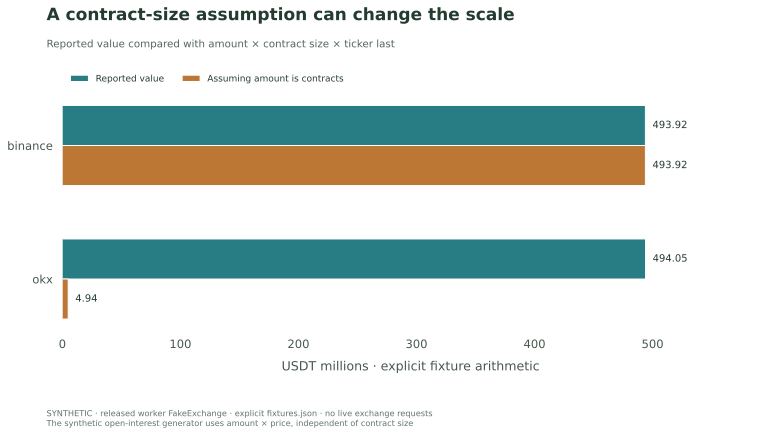

The three fan-outs retain **6 returned measurements and 3 unavailable rows**, rather than replacing errors with zeros. Both valid current rates are **1 bp per eight-hour interval**, or **10.95% per year** under simple repetition. Those are upcoming synthetic rates, not settled history or forecasts. For OKX's stand-in, the reported value is **100 times** the contracts-assumption calculation. The fixture's generator explains the mismatch; we have not established a conversion for a live exchange. No cross-venue aggregate or OI-weighted funding estimate is justified by an unresolved quantity unit.

In [9]:
display(unit_check)
status = con.execute("SELECT * FROM measurement_status ORDER BY measurement,exchange").df()
funding = con.execute("SELECT * FROM funding_now ORDER BY exchange").df()
quotes = con.execute("SELECT * FROM quotes ORDER BY exchange").df()
contracts = con.execute("SELECT * FROM contracts ORDER BY exchange,symbol").df()
assert len(status) == 9 and status.error.isna().sum() == 6
assert status.loc[status.error.notna(), "exchange"].eq("kraken").all()
assert np.allclose(unit_check.reported_to_assumed_ratio, [1, 100])
valid = funding.loc[funding.error.isna()]
assert np.allclose(valid.funding_rate_annualized, valid.funding_rate * 8760 / valid.interval_hours)
fig, ax = plt.subplots(figsize=(11, 6.4))
y = np.arange(len(unit_check))
height = 0.30
for values, offset, color, label in [
    (unit_check.reported_value / 1e6, -height / 2, "#287D85", "Reported value"),
    (unit_check.value_if_amount_is_contracts / 1e6, height / 2, "#BD7735", "Assuming amount is contracts"),
]:
    ax.barh(y + offset, values, height=height, color=color, label=label)
    for yy, value in zip(y + offset, values, strict=True):
        ax.text(value + 6, yy, f"{value:,.2f}", va="center", fontsize=10)
ax.set(
    yticks=y,
    yticklabels=unit_check.exchange,
    xlabel="USDT millions · explicit fixture arithmetic",
    xlim=(0, 590),
)
ax.invert_yaxis()
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.12), ncol=2, fontsize=9)
finish(
    fig,
    "A contract-size assumption can change the scale",
    "Reported value compared with amount × contract size × ticker last",
    source_label
    + "\nThe synthetic open-interest generator uses amount × price, independent of contract size",
    name="interest-units",
)
prose(
    f"The three fan-outs retain **{int(status.error.isna().sum())} returned measurements and {int(status.error.notna().sum())} unavailable rows**, rather than replacing errors with zeros. Both valid current rates are **1 bp per eight-hour interval**, or **10.95% per year** under simple repetition. Those are upcoming synthetic rates, not settled history or forecasts. For OKX's stand-in, the reported value is **{unit_check.iloc[1].reported_to_assumed_ratio:.0f} times** the contracts-assumption calculation. The fixture's generator explains the mismatch; we have not established a conversion for a live exchange. No cross-venue aggregate or OI-weighted funding estimate is justified by an unresolved quantity unit."
)

### A spot book gives quantity a specific denomination

For this depth experiment we select the Binance **spot** BTC/USDT market, so quantity is BTC and price is USDT per BTC. The ticker's best bid/ask is checked against level 1. We materialize both sides once, calculate cumulative BTC in SQL, and express each price's distance from the ticker midpoint in basis points. This is displayed depth, not a fill guarantee; the fixture has no queue dynamics or fees.

In [10]:
%%sql
CREATE TABLE spot_quote AS SELECT * FROM ccxt.main.ticker('binance','BTC/USDT');
CREATE TABLE book AS SELECT * FROM ccxt.main.order_book('binance','BTC/USDT',depth=>{{DEPTH}});
CREATE TABLE ladder AS
SELECT b.*,sum(amount) OVER(PARTITION BY side ORDER BY level) AS cumulative_btc,
 10000*(price/((q.bid+q.ask)/2)-1) AS distance_bps
FROM book b CROSS JOIN spot_quote q;
SELECT side,count(*) AS levels,sum(amount) AS displayed_btc,min(ts) AS source_ts
FROM ladder GROUP BY side ORDER BY side;

,side,levels,displayed_btc,source_ts
0,ask,5,15.0,2026-01-01
1,bid,5,15.0,2026-01-01


In [11]:
%%sql ladder <<
SELECT * FROM ladder ORDER BY side,level;

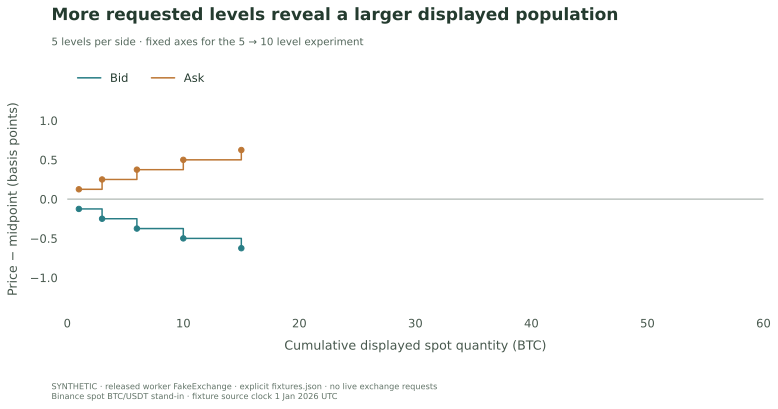

The scan returns **10 levels** across two sides, totaling **15 BTC on each side**. Level 1 agrees with the separate ticker; all fixture snapshots use the same frozen source clock. Real independent calls need not be synchronized. Increasing requested depth changes which resting rows we receive, not the midprice or the meaning of a BTC.

7959

In [12]:
assert len(ladder) == 2 * DEPTH and not ladder.duplicated(["side", "level"]).any()
assert ladder.groupby("side").amount.sum().eq(DEPTH * (DEPTH + 1) / 2).all()
spot = con.execute("SELECT * FROM spot_quote").df().iloc[0]
assert ladder.loc[(ladder.side == "bid") & (ladder.level == 1), "price"].iloc[0] == spot.bid
assert ladder.loc[(ladder.side == "ask") & (ladder.level == 1), "price"].iloc[0] == spot.ask
fig, ax = plt.subplots(figsize=(11, 6.0))
for side, color in [("bid", "#287D85"), ("ask", "#BD7735")]:
    part = ladder.loc[ladder.side.eq(side)]
    ax.step(part.cumulative_btc, part.distance_bps, where="post", color=color, label=side.title())
    ax.scatter(part.cumulative_btc, part.distance_bps, color=color, s=30)
ax.axhline(0, color="#9BA6A0", linewidth=1)
ax.set(
    xlabel="Cumulative displayed spot quantity (BTC)",
    ylabel="Price − midpoint (basis points)",
    xlim=(0, 60),
    ylim=(-1.4, 1.4),
)
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.12), ncol=2)
finish(
    fig,
    "More requested levels reveal a larger displayed population",
    f"{DEPTH} levels per side · fixed axes for the 5 → 10 level experiment",
    source_label + "\nBinance spot BTC/USDT stand-in · fixture source clock 1 Jan 2026 UTC",
    name="spot-depth",
)
prose(
    f"The scan returns **{len(ladder)} levels** across two sides, totaling **{DEPTH * (DEPTH + 1) / 2:g} BTC on each side**. Level 1 agrees with the separate ticker; all fixture snapshots use the same frozen source clock. Real independent calls need not be synchronized. Increasing requested depth changes which resting rows we receive, not the midprice or the meaning of a BTC."
)
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/02-audit.json").write_text(
    json.dumps(
        {
            "fixture_sha256": fixture_hash,
            "depth": DEPTH,
            "unit_check": unit_check.to_dict("records"),
            "status": status.to_dict("records"),
            "funding": funding.to_dict("records"),
            "quotes": quotes.to_dict("records"),
            "contracts": contracts.to_dict("records"),
            "ladder": ladder.to_dict("records"),
        },
        default=str,
        indent=2,
    )
    + "\n"
)

### Experiment: request ten levels, hold measurements fixed

Change only `DEPTH = 5` to `10`. Both sides should extend from 15 to 55 displayed BTC; the original first five rows on each side must remain unchanged. The quote, contract definitions, current funding, open-interest calculations and error rows should be identical. The fixed chart axes make the extension visible.

Restore **5**. The result demonstrates requested-depth and measurement contracts on a controlled source. It does not validate current exchange metadata, quantity normalization, simultaneous snapshots, executable liquidity or investment returns.

In [13]:
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
restore_fixture()
atexit.unregister(restore_fixture)
assert os.environ.get("VGI_CCXT_FIXTURES") == previous_fixture
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-ccxt](https://github.com/Query-farm/vgi-ccxt)